In [6]:
import nbformat

with open("C:/Users/user/Downloads/k-means-clustering-of-iris-dataset/k-means-clustering-of-iris-dataset.ipynb", "r", encoding="utf-8") as f:
    notebook = nbformat.read(f, as_version=4)

notebook

{'cells': [{'cell_type': 'markdown',
   'execution_count': None,
   'metadata': {'papermill': {'duration': 0.009283,
     'end_time': '2020-08-30T16:00:19.36675',
     'exception': False,
     'start_time': '2020-08-30T16:00:19.357467',
     'status': 'completed'},
    'tags': []},
   'source': 'The Iris flower data set or Fisher\'s Iris data set is a multivariate data set introduced by the British statistician, eugenicist, and biologist Ronald Fisher in his 1936 paper The use of multiple measurements in taxonomic problems as an example of linear discriminant analysis.[[1](https://en.wikipedia.org/wiki/Iris_flower_data_set#:~:text=The%20Iris%20flower%20data%20set,example%20of%20linear%20discriminant%20analysis.)] It is sometimes called Anderson\'s Iris data set because Edgar Anderson collected the data to quantify the morphologic variation of Iris flowers of three related species.[2] Two of the three species were collected in the Gaspé Peninsula "all from the same pasture, and picked o

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [8]:
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

df


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [9]:
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [11]:
iris=load_iris()
X=iris.data[:,:2]
print("Dataset shape:",X.shape)

Dataset shape: (150, 2)


In [14]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [15]:
inertia=[]
for k in range(1,11):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

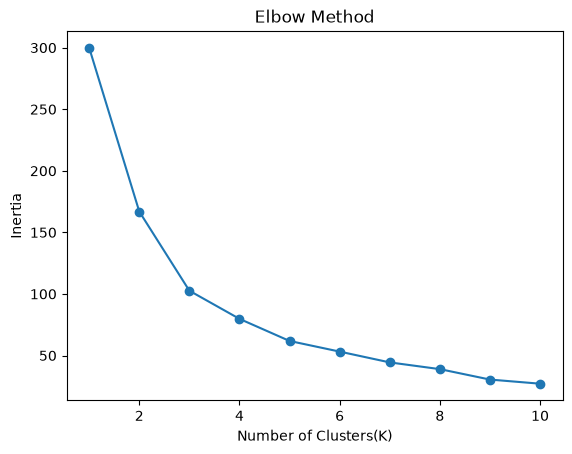

In [16]:
plt.plot(range(1,11),inertia,marker='o')
plt.xlabel("Number of Clusters(K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [17]:
kmeans=KMeans(n_clusters=3,random_state=42,n_init=10)
clusters=kmeans.fit_predict(X_scaled)

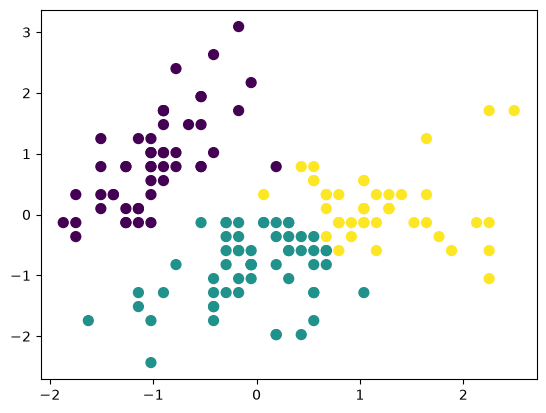

In [22]:
plt.scatter(
    X_scaled[:, 0],X_scaled[:, 1],
    c=clusters,cmap='viridis',s=50
)

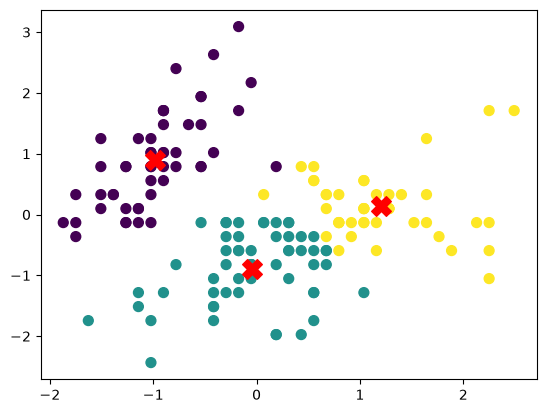

In [23]:
plt.scatter(
    X_scaled[:, 0],X_scaled[:, 1],
    c=clusters,cmap='viridis',s=50
)
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    marker='X',s=200,color='red',label='Centroids'
)

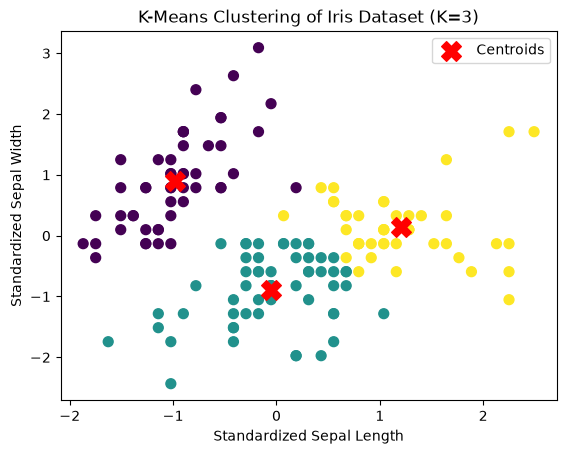

In [25]:
plt.scatter(
    X_scaled[:, 0],X_scaled[:, 1],
    c=clusters,cmap='viridis',s=50
)
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    marker='X',s=200,color='red',label='Centroids'
)
plt.xlabel('Standardized Sepal Length')
plt.ylabel('Standardized Sepal Width')
plt.title('K-Means Clustering of Iris Dataset (K=3)')

plt.legend()
plt.show()

In [28]:
print("\nFirst 10 cluster assignments:")
print(clusters[:10])


First 10 cluster assignments:
[0 0 0 0 0 0 0 0 0 0]


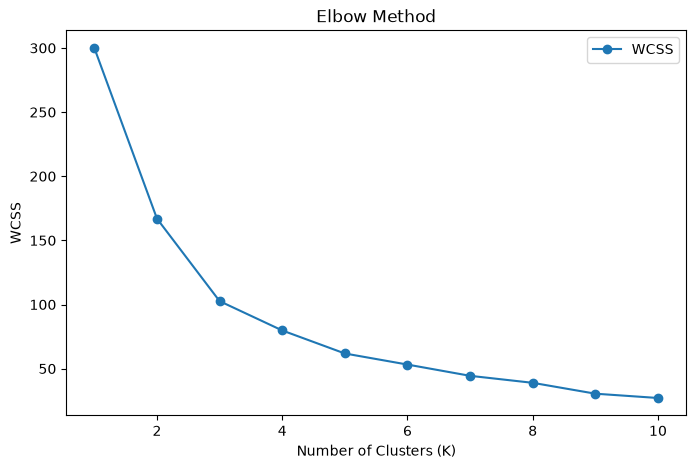

In [29]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.legend(['WCSS'])
plt.show()

In [31]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

    print("K =", k, "Inertia =", kmeans.inertia_)

K = 1 Inertia = 300.0000000000001
K = 2 Inertia = 166.95170933934477
K = 3 Inertia = 102.62263379182495
K = 4 Inertia = 79.76964639756852
K = 5 Inertia = 61.809249095212515
K = 6 Inertia = 53.16893963834243
K = 7 Inertia = 44.39725513624488
K = 8 Inertia = 38.934520958817174
K = 9 Inertia = 30.461648690889973
K = 10 Inertia = 27.105112907918837


In [32]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans.fit(X_scaled)

print("Inertia:", kmeans.inertia_)

Inertia: 102.62263379182495
